In [1]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("mrwellsdavid/unsw-nb15")
print(os.listdir(path))

train = pd.read_csv(os.path.join(path, "UNSW_NB15_testing-set.csv"))   # 175 341 lignes
test = pd.read_csv(os.path.join(path, "UNSW_NB15_training-set.csv"))   # 82 332 lignes

['NUSW-NB15_features.csv', 'UNSW-NB15_1.csv', 'UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv', 'UNSW-NB15_LIST_EVENTS.csv', 'UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']


In [2]:

print("Train :", train.shape)
print("Test  :", test.shape)
train.info()

Train : (175341, 45)
Test  : (82332, 45)
<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              17

In [3]:
train.isnull().sum().sort_values(ascending=False).head(10)

id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
dtype: int64

In [4]:
print("Total valeurs manquantes :", train.isnull().sum().sum())
print()
print(train["service"].value_counts())

Total valeurs manquantes : 0

service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64


In [5]:
print(train["label"].value_counts())
print()
print(train["attack_cat"].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


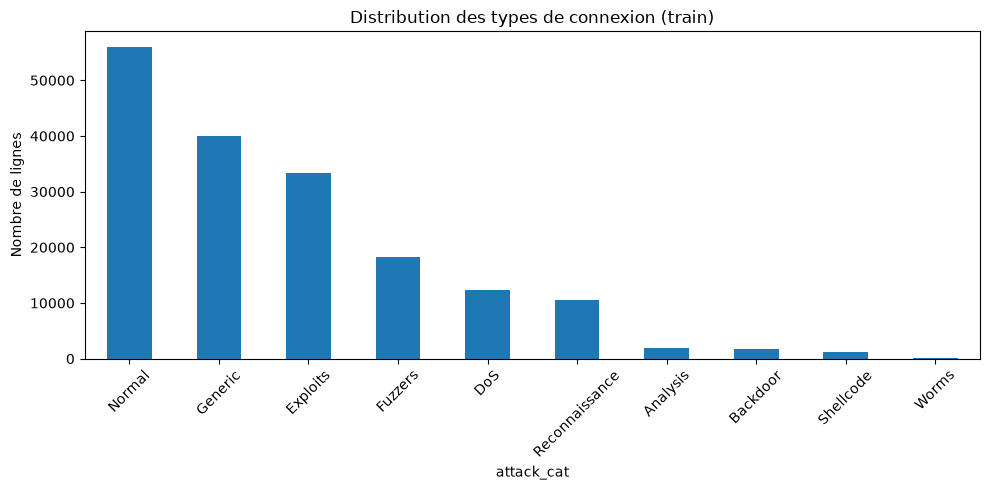

In [6]:
import matplotlib.pyplot as plt

train["attack_cat"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Distribution des types de connexion (train)")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()